---
# Методы статистической обработки информации
---
## Лабораторная работа 5 / Кластерный анализ / Вариант 15
---

---
## Подготовка
---

### Импорт библиотек

In [245]:
import matplotlib.pyplot as plt

from MoSDP_data       import *
from MoSDP_operations import *

### Получение данных варианта

In [246]:
variant  = int(input("Введите номер варианта: "))
var_data = transpose(get_data(variant))

---
## Задание
---

### Функция "Расстояние"

In [247]:
def distance(clusters, i, j):
    k = len(var_data[0])

    min_s = float('inf')
    for S_1 in clusters[i]:
        for S_2 in clusters[j]:
            s = 0
            for l in range(k):
                s += (var_data[S_1][l] - var_data[S_2][l]) ** 2

            s **= 0.5

            if s < min_s:
                min_s = s

    return min_s

### Функция "Показать кластеры"

In [248]:
def show_clusters(clusters):
    print("\n- кластеры:")

    new_clusters = copy(clusters)
    for cluster in new_clusters:
        for i in range(len(cluster)):
            cluster[i] += 1

    print(new_clusters)

### Алгоритм кластерного анализа

In [249]:
associations = []
history      = []
clusters     = [[i] for i in range(len(var_data))]



step = 0
while len(clusters) > 1:
    step += 1
    print(f"{"=" * 5} ШАГ {step} {"=" * 5}")

    show_clusters(clusters)

    n = len(clusters)

    object_1 = object_2 = 0
    min_dist = float('inf')

    R = [[[] for _ in range(n)] for _ in range(n)]
    for i in range(n):
        for j in range(i, n):
            R[i][j] = R[j][i] = distance(clusters, i, j)

            if R[i][j] != 0 and R[i][j] < min_dist:
                min_dist = R[i][j]
                object_1 = i
                object_2 = j

    print(f"\n- R_{step}:")
    matrix_output(R, "5.2f")

    print(f"\n- наиболее близки кластеры {object_1 + 1} и {object_2 + 1}: r = {min_dist}")
    print(f"---- {object_1 + 1:<2}: {clusters[object_1]}")
    print(f"---- {object_2 + 1:<2}: {clusters[object_2]}\n\n\n")

    associations.append((clusters[object_1].copy(), clusters[object_2].copy(), min_dist))

    clusters[object_1] += clusters[object_2]
    clusters.pop(object_2)

    history.append([copy(clusters), min_dist])

===== ШАГ 1 =====

- кластеры:
[[1], [2], [3], [4], [5], [6], [7], [8], [9], [10], [11], [12], [13], [14], [15], [16], [17], [18], [19], [20], [21], [22], [23], [24], [25], [26], [27], [28], [29], [30], [31], [32], [33], [34], [35], [36], [37], [38], [39], [40], [41], [42], [43], [44], [45], [46], [47], [48], [49], [50], [51], [52], [53]]

- R_1:
[ 0.00  | 1.57  | 9.79  | 5.13  | 10.47 | 3.57  | 4.76  | 2.40  | 7.73  | 5.77  | 9.00  | 3.89  | 8.75  | 5.07  | 7.57  | 2.49  | 5.29  | 3.53  | 4.49  | 4.66  | 3.01  | 2.96  | 5.34  | 2.82  | 5.56  | 4.53  | 6.58  | 5.70  | 3.21  | 1.86  | 14.41 | 4.40  | 6.08  | 1.87  | 8.35  | 8.79  | 5.90  | 2.23  | 6.57  | 2.71  | 4.06  | 5.38  | 5.13  | 9.25  | 6.11  | 4.89  | 4.33  | 10.94 | 7.83  | 8.00  | 10.11 | 9.31  | 2.46  ]
[ 1.57  | 0.00  | 8.74  | 4.25  | 10.06 | 2.35  | 5.02  | 3.20  | 7.93  | 6.25  | 9.03  | 4.46  | 8.66  | 4.12  | 6.90  | 2.92  | 6.43  | 4.70  | 5.40  | 6.00  | 4.04  | 4.06  | 4.51  | 4.32  | 4.56  | 5.73  | 6.79  | 6.95  |

### Дендрограмма

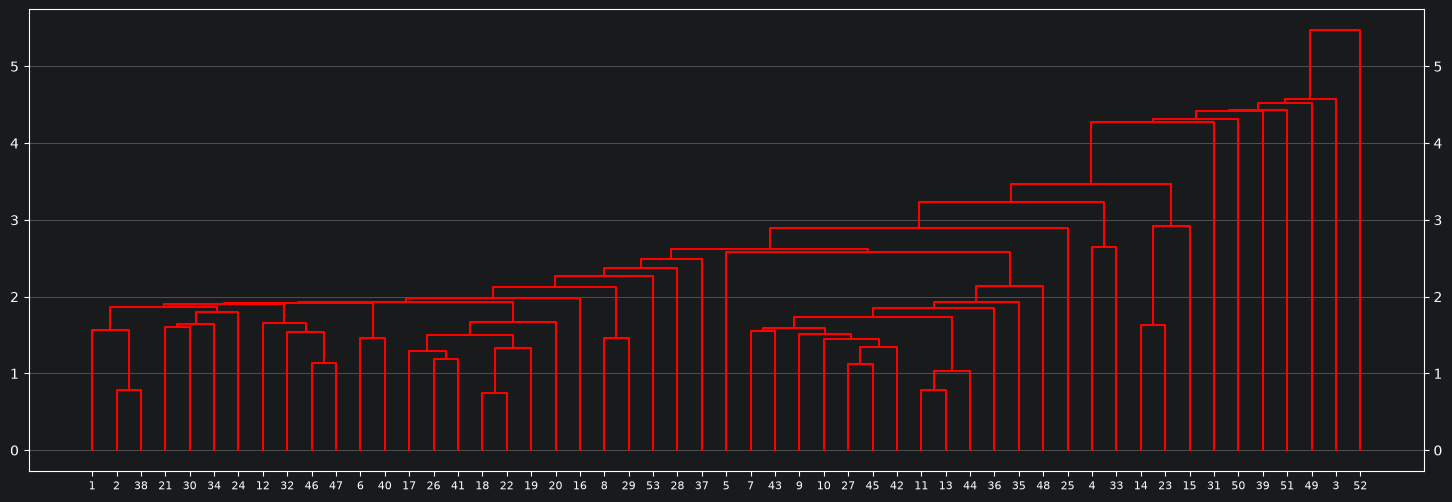

In [250]:
order = clusters[0]
point = {(order[i], ): (i, 0) for i in range(len(order))}

plt.figure(figsize=(18, 6))
for A, B, h in associations:
    xa, ya = point[tuple(A)]
    xb, yb = point[tuple(B)]
    plt.plot([xa, xa, xb, xb], [ya, h, h, yb], color="red")
    point[tuple(A + B)] = ((xa + xb) / 2, h)

plt.xticks(range(len(order)), [(obj + 1) for obj in order], fontsize=8)
plt.tick_params(axis="y", right=True, labelright=True)
plt.grid(axis="y", alpha=0.5)
plt.show()

### Выбор варианта разбиения

In [251]:
height = float(input("Введите высоту разбиения предприятий на кластеры: "))
print(f"Высота разбиения = {height}")

Высота разбиения = 4.0


### Функция "Векторы средних отклонений"

In [252]:
def mean_vectors(func):
    headings = [Y[variant - 1]] + X[variant - 1]
    headings[0] = "y" + str(headings[0])
    for i in range(1, len(headings)):
        headings[i] = "x" + str(headings[i])

    print(f"            | {" | ".join(f"{i:<25}" for i in headings)}")
    print("-" * 180)
    print(f"Вся выборка | {" | ".join(f"{i:{25}}" for i in func(transpose(var_data)))}")

    for l in range(len(history)):
        if history[l][1] > height:
            for cluster in history[l - 1][0]:
                sample = []
                for i in cluster:
                    sample.append(var_data[i])

                print(f"Кластер {history[l - 1][0].index(cluster) + 1:<3} | {" | ".join(f"{i:25}" for i in func(transpose(sample)))}")
            break

### Векторы средних арифметические отклонений

In [253]:
mean_vectors(arithmetic_mean_deviations)

            | y1                        | x5                        | x6                        | x10                       | x14                       | x17                      
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Вся выборка |         7.970377358490566 |        0.7354716981132075 |        0.3011320754716981 |        1.5260377358490564 |         5.969056603773585 |        19.570377358490568
Кластер 1   |         7.810217391304348 |        0.7343478260869566 |       0.30934782608695655 |        1.5484782608695653 |         5.960000000000001 |        19.734565217391303
Кластер 2   |                     12.11 |                      0.68 |                       0.4 |                      1.37 |                      9.76 |                     26.46
Кластер 3   |                      3.78 |                      0.62 |                       0.2 |  

### Векторы средних квадратических отклонений

In [254]:
mean_vectors(root_mean_square_deviations)

            | y1                        | x5                        | x6                        | x10                       | x14                       | x17                      
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Вся выборка |        2.5854826652517997 |       0.05272091124043734 |       0.15372924467802906 |       0.40387434820998896 |        2.3608906731106623 |         4.657878277314663
Кластер 1   |        1.8998174845179605 |       0.04870729674436539 |         0.138633112518541 |       0.42057397318273815 |        2.1591997309792506 |           4.0281669725559
Кластер 2   |                       0.0 |                       0.0 |                       0.0 |                       0.0 |                       0.0 |                       0.0
Кластер 3   |                       0.0 |                       0.0 |                       0.0 |  